# Домашнее задание 2: сверточный классификатор.

### Общая информация

Оценка после штрафа после мягкого дедлайна вычисляется по формуле $M_{\text{penalty}} = M_{\text{full}} \cdot 0.85^{t/1440}$, где $M_{\text{full}}$ — полная оценка за работу без учета штрафа, а $t$ — время в минутах, прошедшее после мягкого дедлайна (округление до двух цифр после запятой). Таким образом, спустя первые сутки после мягкого дедлайна вы не можете получить оценку выше 8.5, а если сдать через четыре дня после мягкого дедлайна, то ваш максимум — 5.22 балла.

### Оценивание и штрафы

Максимально допустимая оценка за работу — 10 баллов. Сдавать задание после указанного срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо оформленные графики. Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

### О задании

В этом задании вам предстоит познакомиться со сверточными сетями и их обучением для классификации изображений с использованием библиотеки PyTorch.


In [1]:
import torch
import torch.nn as nn
# одна из крутейших букв
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split

## 0. Загрузка данных

Работать мы будем с набором данных [CIFAR10](https://www.cs.toronto.edu/~kriz/cifar.html). CIFAR10 представляет собой набор изображений 32х32 пикселя, разделенных на 10 классов.

![title](https://pytorch.org/tutorials/_images/cifar10.png)




Набор данных уже определен в <code>torchvision.datasets</code>, так что возьмем его оттуда. 



In [2]:
def get_cifar10_data(batch_size, transform_train):
    torch.manual_seed(0)
    np.random.seed(0)

    transform_test = transforms.Compose(
        [transforms.ToTensor(),
         # Переводим цвета пикселей в отрезок [-1, 1]
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
    )

    # Загружаем данные
    trainvalset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                               download=True, transform=transform_train)
    testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                           download=True, transform=transform_test)

    # В датасете определено разбиение только на train и test,
    # так что валидацию дополнительно выделяем из обучающей выборки
    train_idx, valid_idx = train_test_split(np.arange(len(trainvalset)), test_size=0.3,
                                            shuffle=True, random_state=0)
    trainset = torch.utils.data.Subset(trainvalset, train_idx)
    valset = torch.utils.data.Subset(trainvalset, valid_idx)

    train_loader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                               shuffle=True, num_workers=2)
    val_loader = torch.utils.data.DataLoader(valset, batch_size=batch_size,
                                             shuffle=False, num_workers=2)
    test_loader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                              shuffle=False, num_workers=2)

    return train_loader, val_loader, test_loader


In [3]:
transform = transforms.Compose(
        [transforms.ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64,
                                                         transform_train=transform)

Посмотрим на изображения:

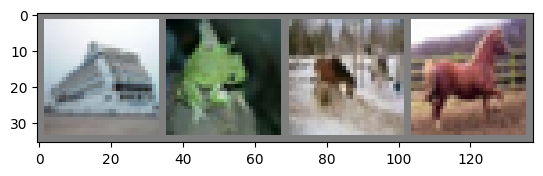

ship frog horse horse


In [4]:
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


dataiter = iter(train_loader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images[:4]))

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
print(*[classes[labels[i]] for i in range(4)])

## 1. Задание сверточной сети (3 балла)

Теперь нам нужно задать сверточную нейронную сеть, которую мы будем обучать классифицировать изображения.

Используем сеть, основанную на одном блоке архитектуры ResNet.

<img src="https://i.ibb.co/2hg962h/basic-block.png" width="500"/>

__Указания:__

- Все сверточные слои должны иметь 32 выходных канала, а также не должны изменять ширину и высоту изображения.
- Выход блока сократите до размерности 32х4х4, применив average pooling.
- Для получения итоговых логитов, распрямите выход пулинга в вектор из 512 элементов, а затем пропустите его через линейный слой.

**Задание 1.1 (3 балла).**

Определите архитектуру сети соответственно схеме и указаниям выше.

Ключевые слова: <code>Conv2d</code>, <code>BatchNorm2d</code>, <code>AvgPool2d</code>.

In [5]:
n_classes = 10

class BasicBlockNet(nn.Module):
    def __init__(self):
        super().__init__()

        # "With residual blocks, inputs can forward propagate faster through the residual connections across layers. In fact, the residual block can be thought of as a special case of the multi-branch Inception block: it has two branches one of which is the identity mapping."
        # почему это называют шорткатом я хз
        self.shortcut = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=1)
        
        # канала 3, нам нужно превратить их в 32
        # паддинг 1 для сохранения размера
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)

        # 32/4 = 8, поэтому берем пулллинг по 8
        self.pool = nn.AvgPool2d(kernel_size=8)

        # 32*4*4 = 512, выход — количество классов, мы указали 10
        self.fc = nn.Linear(512, n_classes)

    def forward(self, x):
        stub = self.shortcut(x)
        # свертка, норма, релу
        out = F.relu(self.bn1(self.conv1(x)))
        
        # свертка, норма
        out = self.bn2(self.conv2(out))
        # добавляем огрызок
        out += stub
        # и только потом релу
        out = F.relu(out)

        # пулинг до 4x4
        out = self.pool(out)

        # 32x4x4 дает нам 512, поэтому можно юзнуть -1 в параметре размера, но можно и 512
        # .size(0) - размер батча
        out = out.view(out.size(0), 512)

        # нейронный слой до 10 классов
        out = self.fc(out)

        return out

In [6]:
net = BasicBlockNet()
net

BasicBlockNet(
  (shortcut): Conv2d(3, 32, kernel_size=(1, 1), stride=(1, 1))
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): AvgPool2d(kernel_size=8, stride=8, padding=0)
  (fc): Linear(in_features=512, out_features=10, bias=True)
)

Проверим, что выход сети имеет корректную размерность:

In [7]:
assert net(torch.zeros((10, 3, 32, 32))).shape == (10, 10)

Чтобы проводить вычисления на GPU, в PyTorch необходимо руками перекладывать объекты, с которыми вы хотите проводить вычисления, на графический ускоритель. Это делается следующим образрм:

In [8]:
device = torch.device('mps:0' if torch.mps.is_available() else 'cpu')
print(device)

mps:0


In [9]:
net = net.to(device)

Подключение GPU в google.colab:

**Среда выполнения** -> **Сменить среду выполнения** -> **Аппаратный ускоритель** -> **GPU**

## 2. Обучение и тестирование модели (3 балла)

**Задание 2.1 (2 балла).** Переходим к обучению модели. Заполните пропуски в функциях <code>test</code> и <code>train_epoch</code>. В качестве функции потерь будем использовать [кросс-энтропию](https://pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html), а в качестве метрики качества accuracy.

In [10]:
def test(model, loader):
    loss_log = []
    acc_log = []
    model.eval()

    for data, target in loader:
        # чтоби работало быстра!
        data = data.to(device)
        target = target.to(device)

        # получаем логиты
        output = model(data)
        # лосс по кэ
        loss = F.cross_entropy(output, target)
        # добавляем лосс
        loss_log.append(loss.item())

        # считаем акк
        pred = output.argmax(dim=1)
        acc = (pred == target).float().mean()
        acc_log.append(acc.item())

    return np.mean(loss_log), np.mean(acc_log)

def train_epoch(model, optimizer, train_loader):
    loss_log = []
    acc_log = []
    model.train()

    for data, target in train_loader:
        # чтоби работало быстра брад!
        data = data.to(device)
        target = target.to(device)

        # зануляем градиенты
        optimizer.zero_grad()
        # логиты
        output = model(data)
        # кэ
        loss = F.cross_entropy(output, target)

        loss.backward()
        # шагаем по градиенту
        optimizer.step()
        # лосс
        loss_log.append(loss.item())
        # и акк
        pred = output.argmax(dim=1)
        acc = (pred == target).float().mean()
        acc_log.append(acc.item())

    return loss_log, acc_log

def train(model, optimizer, n_epochs, train_loader, val_loader, scheduler=None):
    train_loss_log, train_acc_log, val_loss_log, val_acc_log = [], [], [], []

    for epoch in range(n_epochs):
        train_loss, train_acc = train_epoch(model, optimizer, train_loader)
        val_loss, val_acc = test(model, val_loader)

        train_loss_log.extend(train_loss)
        train_acc_log.extend(train_acc)

        val_loss_log.append(val_loss)
        val_acc_log.append(val_acc)

        print(f"Epoch {epoch}")
        print(f" train loss: {np.mean(train_loss)}, train acc: {np.mean(train_acc)}")
        print(f" val loss: {val_loss}, val acc: {val_acc}\n")

        if scheduler is not None:
            scheduler.step()

    return train_loss_log, train_acc_log, val_loss_log, val_acc_log


Запустим обучение модели. В качестве оптимизатора будем использовать стохастический градиентный спуск, который является де-факто стандартом в задачах компьютерного зрения (наравне с <code>Adam</code>).

__Замечание:__ Для достижения наилучшего качества в нашем случае потребуется обучать модель несколько сотен эпох. Однако в целях экономии вашего времени и сил, во всех экспериментах мы ограничимся 20 эпохами.

In [19]:
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
train_loss_log, train_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader)

Epoch 0
 train loss: 0.8464873476699676, train acc: 0.7051612692297704
 val loss: 0.984950656586505, val acc: 0.6665558510638298

Epoch 1
 train loss: 0.8279822772774008, train acc: 0.7130370201096892
 val loss: 0.9198618110190047, val acc: 0.6886746454746165

Epoch 2
 train loss: 0.8185683630502202, train acc: 0.7148855772053302
 val loss: 0.9182417542376416, val acc: 0.6895390071767442

Epoch 3
 train loss: 0.806007104065998, train acc: 0.7212841146824782
 val loss: 0.8790575344511803, val acc: 0.7009751773895101

Epoch 4
 train loss: 0.7977130206019176, train acc: 0.723805987202925
 val loss: 0.9009887401093828, val acc: 0.6936391843126175

Epoch 5
 train loss: 0.7893853811938758, train acc: 0.7259361126087266
 val loss: 0.9134612012416758, val acc: 0.6883200353764473

Epoch 6
 train loss: 0.7766823982189952, train acc: 0.7297964547190413
 val loss: 0.9587687182933726, val acc: 0.6796764183551707

Epoch 7
 train loss: 0.7743056056377439, train acc: 0.7317143836666504
 val loss: 0.88

Посчитайте точность на тестовой выборке:

In [20]:
test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")

test loss: 0.8718, test accuracy: 0.7053


Если вы все сделали правильно, у вас должна была получиться точность $\ge 67\%$.

**Задание 2.2 (1 балл).** Постройте графики зависимости функции потерь и точности классификации от номера шага оптимизатора. На каждом графике расположите данные и для обучающей и для валидационной выборки, итого у вас должно получиться два графика. Обратите внимание, что на обучающей выборке эти данные считаются по каждому батчу, на валидационной же они считаются по всей выборке раз в эпоху.

[    0.           575.78947368  1151.57894737  1727.36842105
  2303.15789474  2878.94736842  3454.73684211  4030.52631579
  4606.31578947  5182.10526316  5757.89473684  6333.68421053
  6909.47368421  7485.26315789  8061.05263158  8636.84210526
  9212.63157895  9788.42105263 10364.21052632 10940.        ]


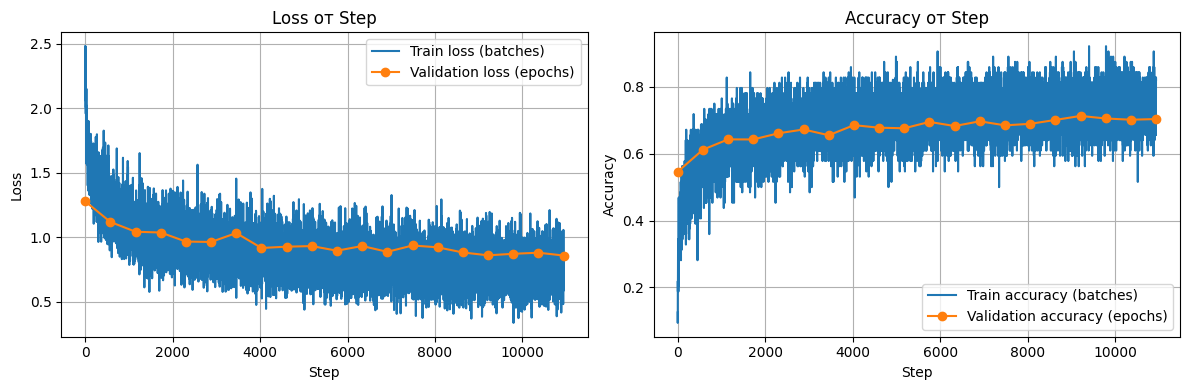

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. График функции потерь
plt.figure(figsize=(12, 4))

# график лосса
plt.subplot(1, 2, 1)
# кривая трэйна + лосса
plt.plot(train_loss_log, label='Train loss (batches)')
# еще нам нужно нанести эпохи, но они реже, поэтому воспользуемся такой имбой как линспейс
val_loss_plot = np.linspace(0, len(train_loss_log), len(val_loss_log))
plt.plot(val_loss_plot, val_loss_log, label='Validation loss (epochs)', marker='o')
plt.xlabel('Step')
plt.ylabel('Loss')
plt.title('Loss от Step')
plt.legend()
plt.grid(True)

# 2. График точности
plt.subplot(1, 2, 2)
plt.plot(train_acc_log, label='Train accuracy (batches)')
val_acc_plot = np.linspace(0, len(train_acc_log), len(val_acc_log))
print(val_acc_plot)
plt.plot(val_acc_plot, val_acc_log, label='Validation accuracy (epochs)', marker='o')
plt.xlabel('Step')
plt.ylabel('Accuracy')
plt.title('Accuracy от Step')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 3. Расписание длины шага (2 балла)

С курса "Машинное обучение 1" вы уже должны знать, что сходимость стохастического градиентного спуска мы можем теоретически гарантировать только если будем определенным образом со временем уменьшать длину шага. На практике при обучении нейронных сетей такая техника оказывается очень полезной, однако теоретически обоснованными способами уменьшения длины шага фантазия не ограничивается.

Одним из простейших способов является кусочно постоянная функция: на нескольких фиксированных эпохах уменьшаем длину шага в константу раз.

In [ ]:
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
tr_loss_log, tr_acc_log, vl_loss_log, vl_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

Epoch 0
 train loss: 1.4877691618703184, train acc: 0.46862349834912875
 val loss: 1.2817850531415735, val acc: 0.5448803191489362

Epoch 1
 train loss: 1.1685285509395424, train acc: 0.5873596238915619
 val loss: 1.1407957612199986, val acc: 0.5992242908224147

Epoch 2
 train loss: 1.0730612149404215, train acc: 0.6270362692297704
 val loss: 1.1777360023336207, val acc: 0.5884973404255319

Epoch 3
 train loss: 1.0166793778348013, train acc: 0.647231653142019
 val loss: 1.004201416512753, val acc: 0.6549645390916378

Epoch 4
 train loss: 0.9675311600922231, train acc: 0.6640033298044362
 val loss: 0.9648894322679398, val acc: 0.6628989361702128

Epoch 5
 train loss: 0.9365433052972204, train acc: 0.6759597806215722
 val loss: 0.9210113568508879, val acc: 0.6844193263256804

Epoch 6
 train loss: 0.9136567134307987, train acc: 0.6814850482687872
 val loss: 0.9246119542324797, val acc: 0.6773492906955962

Epoch 7
 train loss: 0.9001637059766152, train acc: 0.68539027812494
 val loss: 0.90

Посчитайте точность на тестовой выборке:

In [ ]:
test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")

test loss: 0.8316, test accuracy: 0.7163


**Задание 3.0 (0.5 баллов).** Здесь может возникнуть вопрос: а что будет, если мы не будем уменьшать длину шага в процессе обучения, а сразу возьмем констатную, равную значению нашей кусочно-постоянной функции на последних эпохах, то есть $0.001$ в нашем случае. Запустите обучение и проверьте, что в таком случае мы получим худшее качество на тестовой выборке.

In [ ]:
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9) # заменим на 0.001
# и не даем шедулер
tr_loss_log, tr_acc_log, vl_loss_log, vl_acc_log = train(net, optimizer, 20, train_loader, val_loader)

test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.8275473237691457, train acc: 0.36047678897106233
 val loss: 1.5986225665883815, val acc: 0.4435948581137556

Epoch 1
 train loss: 1.519627476305151, train acc: 0.47017008354938444
 val loss: 1.442179972567457, val acc: 0.48747783683715984

Epoch 2
 train loss: 1.3957428740409, train acc: 0.5106220619116231
 val loss: 1.3484186131903466, val acc: 0.5171542553191489

Epoch 3
 train loss: 1.3199926377214506, train acc: 0.5364528923845379
 val loss: 1.2812679184244034, val acc: 0.5475842198158832

Epoch 4
 train loss: 1.2658508800283428, train acc: 0.5561667536904651
 val loss: 1.2307354856044688, val acc: 0.5683289006669471

Epoch 5
 train loss: 1.2200293718569892, train acc: 0.5725752481376885
 val loss: 1.2250261144435153, val acc: 0.5697030142266699

Epoch 6
 train loss: 1.1806593991720697, train acc: 0.5897060263309444
 val loss: 1.1671952486038208, val acc: 0.589029255319149

Epoch 7
 train loss: 1.1434558782542645, train acc: 0.6013849895222749
 val loss: 1.12

кажется и правда аккураси упал((

**Задание 3.1 (1.5 балла).** Изучите, какие еще способы уменьшения длины шага представлены в <code>torch.optim.lr_scheduler</code>. Выберите несколько из них, объясните, как они устроены, и обучите модель с ними. Удалось ли добиться улучшения качества на тестовой выборке?

In [ ]:
# экпонинциально уменьшается 
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.95)
tr_loss_log, tr_acc_log, vl_loss_log, vl_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")

# косинусовская кривая, вроде говорят что хорошая практика 
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
tr_loss_log, tr_acc_log, vl_loss_log, vl_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")

# циклическая, когда как лернинг рейт
# вроде хорошая тем что может внезапно выбраться из локального минимума
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = torch.optim.lr_scheduler.CyclicLR(
    optimizer,
    base_lr=0.001,   # мин шаг
    max_lr=0.1,      # макс шаг
    step_size_up=2000,  # сколько итераций до пика
    mode="triangular"   # форма цикла
)
tr_loss_log, tr_acc_log, vl_loss_log, vl_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")


Epoch 0
 train loss: 1.4851691073429867, train acc: 0.472210433517993
 val loss: 1.2723217441680583, val acc: 0.5528147163543295

Epoch 1
 train loss: 1.1746893123037419, train acc: 0.5895550404649766
 val loss: 1.0613020866475207, val acc: 0.6301861702127659

Epoch 2
 train loss: 1.0569015941846522, train acc: 0.6286195808616373
 val loss: 1.027362529267656, val acc: 0.6454787234042553

Epoch 3
 train loss: 0.9948188407547514, train acc: 0.6531486680128457
 val loss: 1.0385531496494373, val acc: 0.6380762412192974

Epoch 4
 train loss: 0.9487960758113338, train acc: 0.6684023243199755
 val loss: 0.977769728670729, val acc: 0.6558067375041069

Epoch 5
 train loss: 0.9154219899796481, train acc: 0.6815013711151737
 val loss: 0.9836740744874832, val acc: 0.6614361702127659

Epoch 6
 train loss: 0.8910229050263191, train acc: 0.6906054126715093
 val loss: 0.9337455490802197, val acc: 0.6788563829787234

Epoch 7
 train loss: 0.8678328514208088, train acc: 0.6971712588610117
 val loss: 0.88

Your answers here: <br>
MultiStepLR: 0.7163 <br>
ExponentialLR: 0.7015 <br>
CosineAnnealingLR: 0.7199 <br>
CyclicLR: 0.6786 <br>

В целом результат получилось поднять: <br>
Мульти Степ показал топ 2 по тесту, ну и не зря считается проверенной классикой <br>
Экспонента не проканало в этот раз, но тоже неплохой результат <br>
Косинус почти 72%, что явлется топ 1 и очень хороший результат <br>
Циклическая фигня нестабильна и показала результат не оч


## 4. Аугментации данных (2 балла)

Еще одной стандартной техникой, применяющейся в глубинном обучении, а особенно часто в компьютерном зрении, являются аугментации данных. Суть аугментаций состоит в том, что мы можем некоторым синтетическим образом видоизменять объекты обучающей выборки, тем самым расширяя ее, а также делая итоговую модель более устойчивой к таким изменениям.

Простейшая аугментация, которую можно применить к картинкам — разворот картинки по горизонтальной оси. То есть при обучении модели с вероятностью $0.5$ мы будем разворачивать картинку из обучающей выборки.

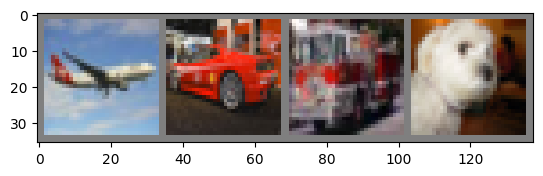

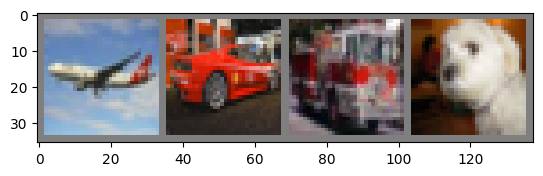

In [ ]:
dataiter = iter(train_loader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images[:4]))

imshow(torchvision.utils.make_grid(transforms.functional.hflip(images[:4])))

Наиболее удобным способом работы с аугментациями в PyTorch является их задание в списке <code>transforms</code>, который затем передается в загрузчик данных. Обучим нашу сеть, применяя горизонтальные повороты:

In [ ]:
transform = transforms.Compose(
        [transforms.RandomHorizontalFlip(),
         transforms.ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64, transform_train=transform)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
tr_loss_log, tr_acc_log, vl_loss_log, vl_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

Epoch 0
 train loss: 1.5033799747662309, train acc: 0.46524467873616887
 val loss: 1.3096252527642758, val acc: 0.5265735815180109

Epoch 1
 train loss: 1.2103723017345618, train acc: 0.5718529641737232
 val loss: 1.1169860997098557, val acc: 0.611502659574468

Epoch 2
 train loss: 1.0895197745650953, train acc: 0.6172956385167905
 val loss: 1.1177513165676847, val acc: 0.6201462765957447

Epoch 3
 train loss: 1.021795680034749, train acc: 0.6471051514911478
 val loss: 0.9902389176348423, val acc: 0.6536347518575952

Epoch 4
 train loss: 0.9791499357772702, train acc: 0.6616487659963437
 val loss: 0.9685844152531725, val acc: 0.6641179077168728

Epoch 5
 train loss: 0.9434650610090392, train acc: 0.6740540937270282
 val loss: 0.9962356422809844, val acc: 0.6553191489361702

Epoch 6
 train loss: 0.9172789673482696, train acc: 0.6836723034734917
 val loss: 0.9459540245380808, val acc: 0.6707003546522019

Epoch 7
 train loss: 0.9031259847951327, train acc: 0.6863043549073897
 val loss: 0.

Посчитайте точность на тестовой выборке:

In [ ]:
test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")

test loss: 0.8107, test accuracy: 0.7208


аккураси заметно увеличилась, это радует

**Задание 4.1 (2 балла).** Изучите, какие еще способы аугментаций изображений представлены в <code>torchvision.transforms</code>. Выберите несколько из них, объясните, как они устроены, и обучите модель с ними (по отдельности и вместе). Удалось ли добиться улучшения качества на тестовой выборке?

In [ ]:
# случайный кроп, можно указать и другой рамер, но мы себе такого не можем позволить
transform = transforms.Compose([
    transforms.RandomCrop(32, padding=5), # за счет кропа на тот же размер, мы научим модель обрабатывать смещения
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)
train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64, transform_train=transform)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
tr_loss_log, tr_acc_log, vl_loss_log, vl_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)
test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.72002616857044, train acc: 0.3772974340636726
 val loss: 1.577733291463649, val acc: 0.42209663124794655

Epoch 1
 train loss: 1.4736669608400335, train acc: 0.4713494058500914
 val loss: 1.3892702041788305, val acc: 0.5028147163543295

Epoch 2
 train loss: 1.35525127117551, train acc: 0.5171511817239974
 val loss: 1.263081939169701, val acc: 0.5534796099713508

Epoch 3
 train loss: 1.2593365535003829, train acc: 0.5552730804387569
 val loss: 1.3792945506724905, val acc: 0.515669326198862

Epoch 4
 train loss: 1.2074953615120603, train acc: 0.573640310786106
 val loss: 1.1688001143171431, val acc: 0.5899822694190004

Epoch 5
 train loss: 1.186906765649262, train acc: 0.5827321101804103
 val loss: 1.338976298494542, val acc: 0.5241578014607126

Epoch 6
 train loss: 1.1567438755872264, train acc: 0.5927543092035507
 val loss: 1.139860594779887, val acc: 0.6025709220703612

Epoch 7
 train loss: 1.1364566855936207, train acc: 0.599834323583181
 val loss: 1.1140260569

In [ ]:
# случайный поворот
transform = transforms.Compose([
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)
train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64, transform_train=transform)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
tr_loss_log, tr_acc_log, vl_loss_log, vl_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)
test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.5782113053463058, train acc: 0.43387225776965266
 val loss: 1.3721039919143028, val acc: 0.5039007091775853

Epoch 1
 train loss: 1.3081526439194269, train acc: 0.5325599046904165
 val loss: 1.195599372336205, val acc: 0.5772828014607125

Epoch 2
 train loss: 1.1923011046658922, train acc: 0.5787085400965793
 val loss: 1.1491796541721262, val acc: 0.6008643617021276

Epoch 3
 train loss: 1.1217057814981646, train acc: 0.6044781601407192
 val loss: 1.15291277271636, val acc: 0.6058067375041069

Epoch 4
 train loss: 1.0728369450002528, train acc: 0.6235472708123257
 val loss: 1.0841752625526266, val acc: 0.6166223404255319

Epoch 5
 train loss: 1.0383073557883338, train acc: 0.6361076652022994
 val loss: 1.1401046397838186, val acc: 0.5974955674181593

Epoch 6
 train loss: 1.0037573934473112, train acc: 0.6473173478403736
 val loss: 1.0419097720308508, val acc: 0.6314937944107867

Epoch 7
 train loss: 1.0027413723455705, train acc: 0.6487088665447898
 val loss: 1.0

In [ ]:
# игра с парметрами картинки, ярче, контрастнее и тд
transform = transforms.Compose([
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)
train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64, transform_train=transform)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
tr_loss_log, tr_acc_log, vl_loss_log, vl_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)
test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.587638596294131, train acc: 0.43088110469594953
 val loss: 1.4314665632045016, val acc: 0.49312943258184067

Epoch 1
 train loss: 1.2420708208023086, train acc: 0.5648872095008655
 val loss: 1.1423234541365441, val acc: 0.6024601063829788

Epoch 2
 train loss: 1.111132264137268, train acc: 0.6122151670987689
 val loss: 1.1185721924964418, val acc: 0.6166001773895101

Epoch 3
 train loss: 1.0506847810265787, train acc: 0.6354057847690756
 val loss: 1.079389174187437, val acc: 0.6342863476022761

Epoch 4
 train loss: 1.0208087329236855, train acc: 0.6471500391280194
 val loss: 1.0820420158670303, val acc: 0.6259751772626917

Epoch 5
 train loss: 0.988211009794441, train acc: 0.6602041981773795
 val loss: 1.0315685713544804, val acc: 0.6428856382978724

Epoch 6
 train loss: 0.9685191271292009, train acc: 0.666047760511883
 val loss: 0.9973760470430901, val acc: 0.6534574468085106

Epoch 7
 train loss: 0.9523798945399046, train acc: 0.672136164779419
 val loss: 0.993

In [ ]:
# все и сразу
transform = transforms.Compose([
    #transforms.RandomCrop(32, padding=7),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
train_loader, val_loader, test_loader = get_cifar10_data(batch_size=64, transform_train=transform)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
tr_loss_log, tr_acc_log, vl_loss_log, vl_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)
test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")

Epoch 0
 train loss: 1.626968933633738, train acc: 0.417912640344944
 val loss: 1.4421103802133113, val acc: 0.4846187942839683

Epoch 1
 train loss: 1.36456834441783, train acc: 0.5157882279735161
 val loss: 1.2770071897100894, val acc: 0.5516843972053934

Epoch 2
 train loss: 1.2393764080905392, train acc: 0.5650381953668333
 val loss: 1.174961616637859, val acc: 0.5871453901554676

Epoch 3
 train loss: 1.179529697629172, train acc: 0.5869189083467236
 val loss: 1.1637160326572176, val acc: 0.5955230497299356

Epoch 4
 train loss: 1.1249073302506092, train acc: 0.6061308435700711
 val loss: 1.1581569194793702, val acc: 0.5958998226104899

Epoch 5
 train loss: 1.1013693911937734, train acc: 0.6146554257141824
 val loss: 1.078391947644822, val acc: 0.6184175531914894

Epoch 6
 train loss: 1.0751129010695644, train acc: 0.6266486027994801
 val loss: 1.0648556762553276, val acc: 0.6262411348363186

Epoch 7
 train loss: 1.062986317892615, train acc: 0.6296764820868616
 val loss: 1.0535382

Your answers here:
итак, фух, модели обучились <br>
результат: <br> <br>
горизонтальный переворот: 0.7208 <br>
случайный кроп: 0.6953 <br>
случайный поворот: 0.7102 <br>
игра с параметрами картинок: 0.7121 <br>
все сразу: 0.7113 <br>

горизонтальный переворот показал лучший результат, с параметрами второй лучший

какие выводы: <br>
надо делать аугментацию под датасет, например как мне кажется кроп и поворот не сильно проканал, тк таких картинок которая делала аугментация просто нет в датасете, <br>
а вот переворот и параметры, имеют место быть в датасете, поэтому моделька обучалась норм <br>
все сразу тоже думаю лучше не навешивать, слишком исказиться для нормального восприятия <br>

## Бонус. Логирование в wandb (2 балла)

На практике специалиста по глубинному обучению часто встречаются ситуации, когда нейросеть учится на каком-то удаленном сервере. И обычно вам хочется отслеживать прогресс обучения, особенно когда время обучения модели исчисляется днями или неделями. Для таких целей существует несколько инструментов. Вероятно, самый популярный из них — [wandb](https://wandb.ai/site).

Ваша задача состоит в том, чтобы разобраться как им пользоваться, и повторить задания 2.1 и 2.2 с его использованием. Обучение вы можете запускать в этом же ноутбуке, но теперь вам необходимо через wandb логировать значения функции потерь и точности на обучающей выборке и на валидационной. Результатом работы должны быть ваш код и публичная ссылка на страничку с графиками, идентичными графикам в задании 2.2.

In [14]:
%pip install wandb


[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [15]:
import wandb

wandb.init(project="homework", name="homework")

wandb: Currently logged in as: m0w0kl (m0w0kl-skip) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [16]:
def test(model, loader):
    loss_log = []
    acc_log = []
    model.eval()

    for data, target in loader:
        # чтоби работало быстра!
        data = data.to(device)
        target = target.to(device)

        # получаем логиты
        output = model(data)
        # лосс по кэ
        loss = F.cross_entropy(output, target)
        # добавляем лосс
        loss_log.append(loss.item())

        # считаем акк
        pred = output.argmax(dim=1)
        acc = (pred == target).float().mean()
        acc_log.append(acc.item())

    avg_loss = np.mean(loss_log)
    avg_acc = np.mean(acc_log)
    # Логирование
    wandb.log({f"loss": avg_loss, f"acc": avg_acc})
    return avg_loss, avg_acc

def train_epoch(model, optimizer, train_loader):
    loss_log = []
    acc_log = []
    model.train()

    for data, target in train_loader:
        # чтоби работало быстра брад!
        data = data.to(device)
        target = target.to(device)

        # зануляем градиенты
        optimizer.zero_grad()
        # логиты
        output = model(data)
        # кэ
        loss = F.cross_entropy(output, target)

        loss.backward()
        # шагаем по градиенту
        optimizer.step()
        # лосс
        loss_log.append(loss.item())
        # и акк
        pred = output.argmax(dim=1)
        acc = (pred == target).float().mean()
        acc_log.append(acc.item())
        wandb.log({"train_loss": loss.item(), "train_acc": acc.item()})

    return loss_log, acc_log

def train(model, optimizer, n_epochs, train_loader, val_loader, scheduler=None):
    train_loss_log, train_acc_log, val_loss_log, val_acc_log = [], [], [], []

    for epoch in range(n_epochs):
        train_loss, train_acc = train_epoch(model, optimizer, train_loader)
        val_loss, val_acc = test(model, val_loader)

        train_loss_log.extend(train_loss)
        train_acc_log.extend(train_acc)

        val_loss_log.append(val_loss)
        val_acc_log.append(val_acc)

        print(f"Epoch {epoch}")
        print(f" train loss: {np.mean(train_loss)}, train acc: {np.mean(train_acc)}")
        print(f" val loss: {val_loss}, val acc: {val_acc}\n")

        if scheduler is not None:
            scheduler.step()

    return train_loss_log, train_acc_log, val_loss_log, val_acc_log

In [17]:
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)

wandb.watch(net, log="all")  # отслеживать градиенты, веса и выходы

train_loss_log, train_acc_log, val_loss_log, val_acc_log = train(net, optimizer, 20, train_loader, val_loader, scheduler)

Epoch 0
 train loss: 1.4955790891725795, train acc: 0.46792569860025995
 val loss: 1.2606073848744657, val acc: 0.5623670212765958

Epoch 1
 train loss: 1.177826555490058, train acc: 0.5878615500286248
 val loss: 1.140365035229541, val acc: 0.6011968085106383

Epoch 2
 train loss: 1.0495572267764228, train acc: 0.6352711217494944
 val loss: 1.042231087481722, val acc: 0.6398714539852548

Epoch 3
 train loss: 0.99720814971209, train acc: 0.6528915839177817
 val loss: 1.0107904905968523, val acc: 0.6519281914893617

Epoch 4
 train loss: 0.9632101112353518, train acc: 0.6652152977434329
 val loss: 1.0518998747176311, val acc: 0.640625

Epoch 5
 train loss: 0.9329502773241326, train acc: 0.676416819012797
 val loss: 1.0030028946856235, val acc: 0.6508200353764473

Epoch 6
 train loss: 0.9124611154116922, train acc: 0.6860472708123257
 val loss: 0.9993194950387833, val acc: 0.6575797872340425

Epoch 7
 train loss: 0.9009642157519757, train acc: 0.6865696003711638
 val loss: 0.93683044580703

In [18]:
test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")

test loss: 0.8319, test accuracy: 0.7139


https://wandb.ai/m0w0kl-skip/homework/runs/8gda0aeg